# CP3 - Verifikasi baseline future_7d_mean_sbp
**DATA SINTETIS / SIMULASI. Target belum disetujui final oleh dosen. Bukan diagnosis/validasi klinis.**

Notebook ini hanya membaca dua CSV dan menulis artefak/laporan lokal. Tidak menghubungi database. Jalankan semua sel dari root atau direktori notebooks dengan kernel project. Notebook 01 adalah catatan awal; hasil terverifikasi ada di sini.

Origin = akhir hari t; histori t-6..t; target rerata SBP harian t+1..t+7. Tujuh hari kalender lengkap wajib ada pada kedua jendela. SBP harian merata-ratakan sesi yang lolos gate teknis pasangan pembacaan nomor sama; komponen silang/parsial dan pasangan tidak konsisten berstatus pending_review. Keputusan ilmiah akhir tetap menunggu dosen. Profil statis diasumsikan diketahui sebelum t; ketersediaan data aktual harus diaudit terpisah.

In [1]:
from pathlib import Path
import sys,json
root=Path.cwd().parent if Path.cwd().name=='notebooks' else Path.cwd()
sys.path.insert(0,str(root))
import pandas as pd,numpy as np,joblib
from backend.app.pipeline import prepare
from backend.app.baseline import make_training,partitions,fit_model,leakage_audit,run_experiment,FEATURES
from etl.verify_baseline import write_evidence
from IPython.display import display,Image
profile=root/'data/sample/Data_Responden_Sintetis.csv'
daily=root/'data/sample/Data_Harian_Sintetis.csv'
p,d,s,q=prepare(pd.read_csv(profile,dtype=str,keep_default_na=False),pd.read_csv(daily,dtype=str,keep_default_na=False),synthetic=True)
print('Profiles, ID-days, sessions:',len(p),len(d),len(s))
assert (len(p),len(d),len(s))==(19,570,1140)


Profiles, ID-days, sessions: 19 570 1140


## Feature engineering dan waktu ketersediaan
Fitur numerik histori tidak memakai perilaku/tekanan darah setelah origin. NA tidak diubah nol; rerata histori mengabaikan NA, kemudian imputer median training mengisi fitur kosong. Imputer/scaler hanya fit train, bukan seluruh dataset. Target/fitur yang membutuhkan tanggal hilang tidak dibuatkan data.

In [2]:
frame=make_training(p,d,s)
display(frame.head())
parts=partitions(frame)
print('All windows:',len(frame),'cutoff:',parts['cutoff'])
print('Train / primary test / rolling test:',len(parts['train']),len(parts['test']),len(parts['rolling_test']))
model=fit_model(parts['train'])
display(pd.Series(leakage_audit(parts['train'],parts['test'],model)))


,respondent_id,asof_date,history_start,target_start,target_end,past_7d_sbp,past_7d_dbp,past_7d_sbp_std,age,bmi,past_7d_activity,past_7d_sleep,past_7d_stress,target
0,SIM001,2026-09-07,2026-09-01,2026-09-08,2026-09-14,119.321429,72.464286,1.645960,55,23.417,63.571429,6.480857,2.571429,122.250000
1,SIM001,2026-09-08,2026-09-02,2026-09-09,2026-09-15,119.392857,72.607143,1.715773,55,23.417,65.714286,6.495143,2.857143,122.250000
2,SIM001,2026-09-09,2026-09-03,2026-09-10,2026-09-16,120.178571,72.928571,1.307358,55,23.417,65.714286,6.873714,2.714286,121.535714
3,SIM001,2026-09-10,2026-09-04,2026-09-11,2026-09-17,120.642857,73.178571,1.940440,55,23.417,63.571429,6.814286,3.000000,120.678571
4,SIM001,2026-09-11,2026-09-05,2026-09-12,2026-09-18,120.357143,73.464286,2.012715,55,23.417,66.428571,7.021429,3.285714,121.178571


All windows: 323 cutoff: 2026-09-18
Train / primary test / rolling test: 60 7 42


subject_overlap                                []
shared_measurement_id_dates                     0
train_target_end_max                   2026-09-18
test_origin_min                        2026-09-18
labels_available_before_test                 True
test_overlapping_target_id_days                 0
imputer_matches_training_only                True
scaler_matches_training_only                 True
training_overlapping_target_id_days           288
dtype: object

## Audit split dan overlapping target windows
Group split lama memisahkan ID tetapi kalender sama dan target test berurutan overlap. Itu tidak otomatis berarti imputer/scaler bocor, namun belum validasi masa depan ketat.

Evaluasi utama: 32% ID holdout, seed 42; cutoff tetap 60% kalender, dipilih sebelum melihat skor. Train label harus selesai paling lambat cutoff; origin test pada/setelah cutoff. Target test per ID tidak overlap (stride minimal 7 hari). Window train masih overlap di dalam train dan harus dilaporkan sebagai pengamatan berkaitan. Test sintetis hanya 7 origin dari 7 ID; bukan bukti generalisasi.

In [3]:
import copy
mutated=copy.deepcopy(s)
for row in mutated:
    if str(row['date'])>parts['cutoff']: row['sbp_mean']+=100
changed=partitions(make_training(p,d,mutated))
np.testing.assert_allclose(fit_model(changed['train']).named_steps['regressor'].coef_,model.named_steps['regressor'].coef_)
print('Verified: measurements after fit cutoff cannot change fitted model.')


Verified: measurements after fit cutoff cannot change fitted model.


## Eksekusi eksperimen sebenarnya
Naive: rerata tujuh SBP harian sebelumnya. Pembanding: Linear Regression dengan median imputer dan StandardScaler. Tidak ada tuning. Skor utama, sensitivitas rolling, dan hasil subject-only lama dihitung ulang, bukan ditulis manual.

In [4]:
report=root/'reports/cp3_baseline'
result=run_experiment(profile,daily,root/'models',report)
write_evidence(result,report)
display(pd.DataFrame(result['scores']))
print('Run:',result['run_id'],'train:',result['rows_training'],'test:',result['rows_test'])
for name,evaluation in result['secondary_evaluations'].items():
    print(name,evaluation.get('rows_test'))
    display(pd.DataFrame(evaluation['scores']))


,model,mae,rmse,r2
0,Naive 7-day mean,1.933673,2.234723,0.850309
1,Linear Regression,2.575492,3.113985,0.709343


Run: 5d3bed0d6591cd2bc09d train: 60 test: 7
legacy_subject_only 119


,model,mae,rmse,r2
0,Naive 7-day mean,1.939976,2.318155,0.857057
1,Linear Regression,2.261566,2.924881,0.772441


purged_rolling 42


,model,mae,rmse,r2
0,Naive 7-day mean,1.897109,2.262457,0.861088
1,Linear Regression,2.164962,2.701109,0.802001


## Reload artefak dan hitung ulang metrik
Prediksi dipertahankan pada presisi penuh. JSON manifest mengikat hash model dan metrik. R2 bukan accuracy persen, MAE/RMSE dalam mmHg. Hasil berbeda split tidak boleh ditafsirkan sebagai perbaikan model.

In [5]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
pred=pd.read_csv(report/'primary_predictions.csv')
test=pd.read_csv(report/'test_windows.csv')
reloaded=joblib.load(root/'models/linear_regression_synthetic.joblib')
np.testing.assert_allclose(reloaded.predict(test[FEATURES]),pred.linear,atol=1e-10)
for score,key in zip(result['scores'],['naive','linear']):
    assert np.isclose(score['mae'],mean_absolute_error(pred.actual,pred[key]))
    assert np.isclose(score['rmse'],np.sqrt(mean_squared_error(pred.actual,pred[key])))
    assert np.isclose(score['r2'],r2_score(pred.actual,pred[key]))
print('Reload and independent score recomputation passed.')


Reload and independent score recomputation passed.


## Error analysis dan visualisasi
Tinjau semua residual, bukan hanya skor rerata. Error besar mungkin terkait variasi yang tidak tertangkap histori, perbedaan subjek, dan sampel kecil; ini hipotesis, bukan sebab terbukti.

,respondent_id,date,target_start,target_end,actual,naive,linear,naive_residual,linear_residual,abs_linear_error
0,SIM009,2026-09-18,2026-09-19,2026-09-25,121.857143,121.178571,116.720810,0.678571,5.136333,5.136333
1,SIM002,2026-09-18,2026-09-19,2026-09-25,122.071429,120.178571,117.669396,1.892857,4.402032,4.402032
2,SIM004,2026-09-18,2026-09-19,2026-09-25,130.321429,128.678571,126.164388,1.642857,4.157040,4.157040
3,SIM017,2026-09-18,2026-09-19,2026-09-25,124.250000,121.250000,125.529338,3.000000,-1.279338,1.279338
4,SIM006,2026-09-18,2026-09-19,2026-09-25,116.035714,116.928571,114.776239,-0.892857,1.259476,1.259476
5,SIM012,2026-09-18,2026-09-19,2026-09-25,110.642857,106.571429,111.589596,4.071429,-0.946739,0.946739
6,SIM001,2026-09-18,2026-09-19,2026-09-25,122.535714,121.178571,123.383198,1.357143,-0.847484,0.847484


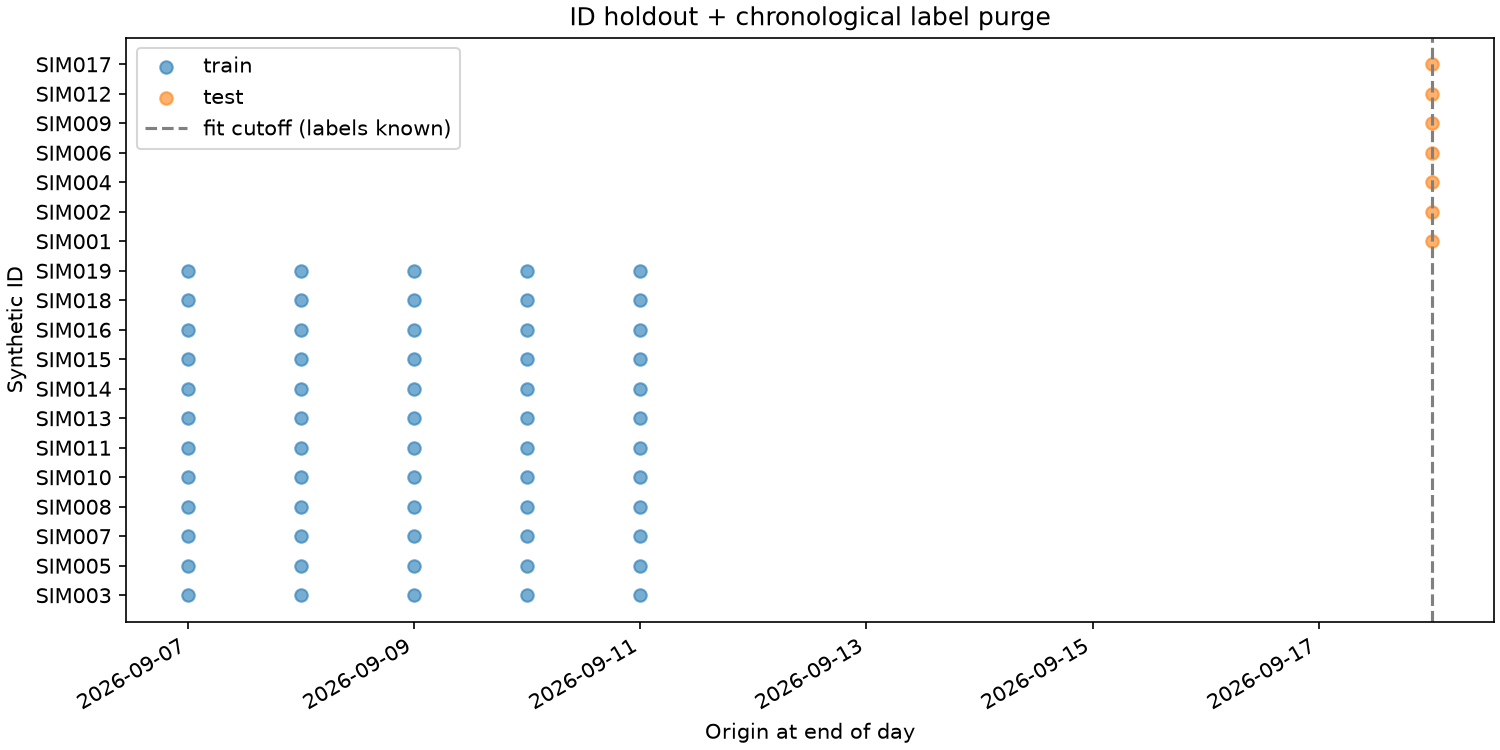

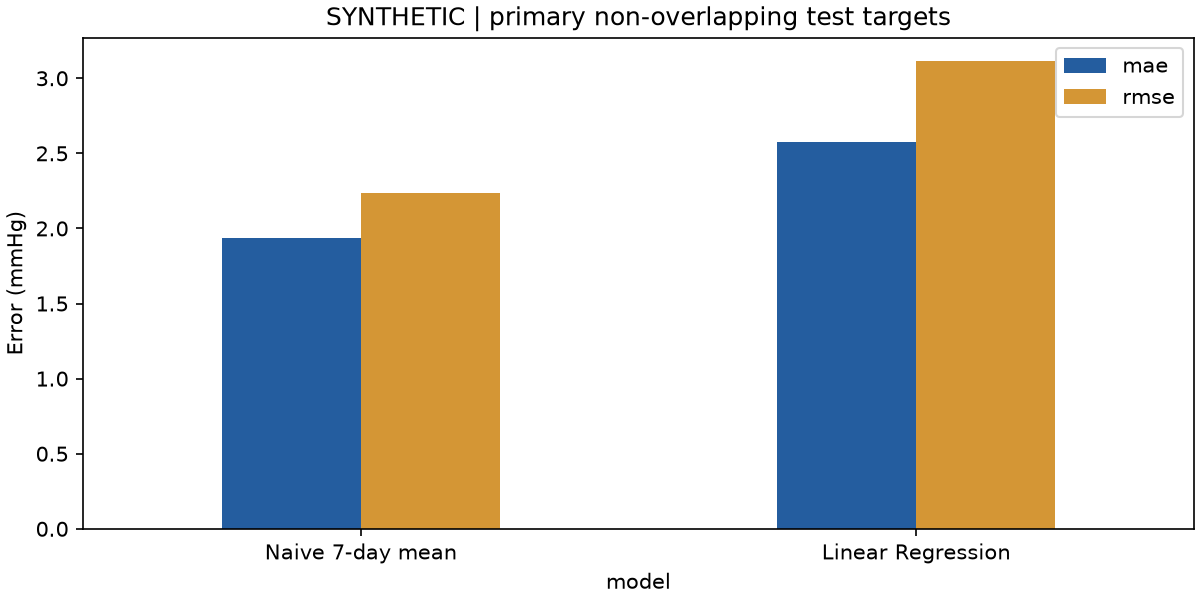

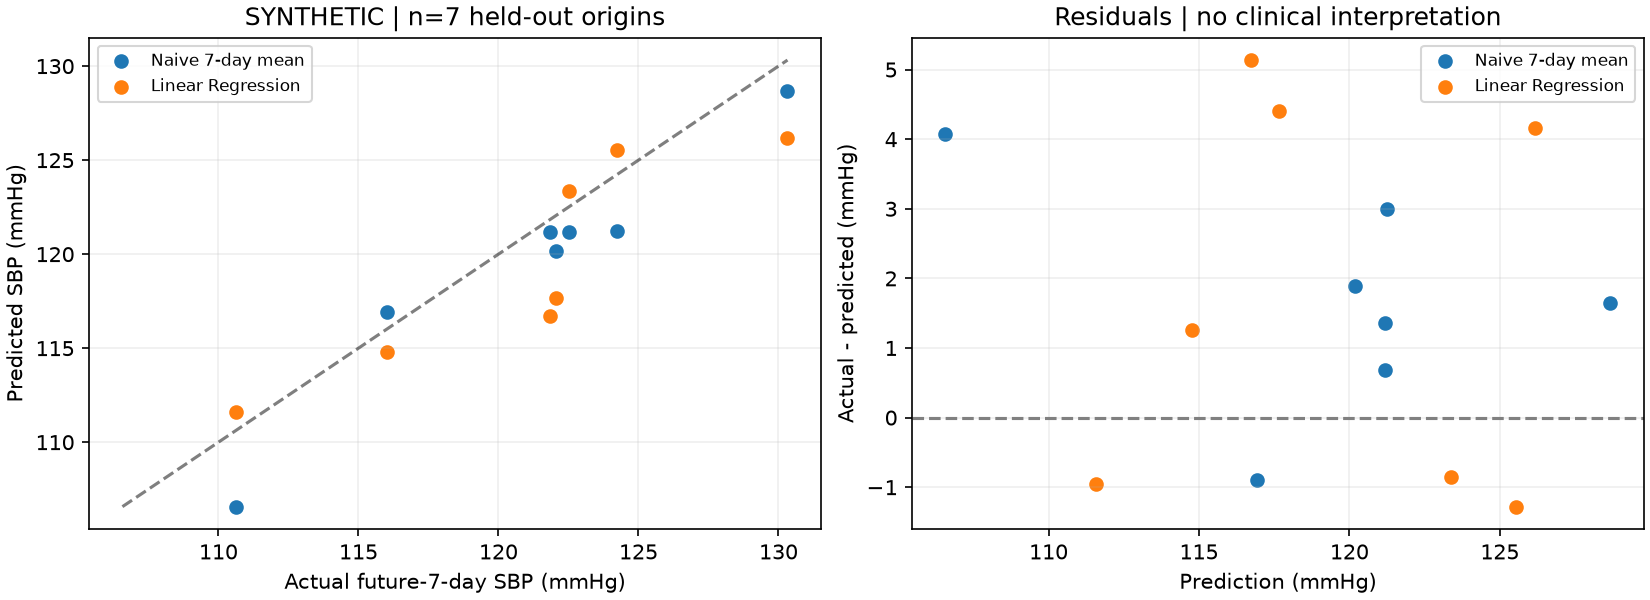

In [6]:
display(pd.read_csv(report/'error_analysis.csv'))
for name in ['split_timeline','model_errors','predictions_residuals']:
    display(Image(filename=str(report/'figures'/f'{name}.png')))


## Kesimpulan terbatas dan keputusan dosen
Metode dengan MAE terkecil pada split utama dapat dilihat pada tabel aktual, tanpa klaim signifikansi/keunggulan umum. Hanya data buatan, satu split, dan sedikit origin test. Persetujuan target, bobot sesi/hari, minimum bacaan valid, definisi tidur, late submission, kriteria responden, kecukupan data primer dan strategi validasi aktual masih harus dikonfirmasi. Tiga algoritma/tuning/model card/deployment final merupakan tahap berikutnya.

Artefak diperbarui secara eksplisit oleh notebook ini; pipeline CP2, CSV sumber, notebook CP2, .env dan warehouse aktif tidak ditulis.